# Chapter 3 - Deep Q-learning
### Deep Reinforcement Learning *in Action*

In [1]:
import os
import random
import copy                      # 新增：之後複製目標網路 model2 要用
from collections import deque    # 新增：經驗回放記憶體

import numpy as np
import torch
from matplotlib import pylab as plt
import gymnasium as gym          # 新增：取代 Gridworld 的環境套件

# 新增：建立 LunarLander 環境（取代 from Environments.Gridworld import Gridworld）
env = gym.make("LunarLander-v3")

# 已刪除：action_set（gymnasium 的 env.step() 直接收整數 0~3，不需要再轉成字母）

print("環境建立成功:", env)   # 確認用

環境建立成功: <TimeLimit<OrderEnforcing<PassiveEnvChecker<LunarLander<LunarLander-v3>>>>>


##### Listing 3.1 - Creating a Gridworld game

In [2]:
# 重設環境，取得初始狀態（對應 Gridworld(...) 建立新遊戲）
state, info = env.reset(seed=0)

# Gridworld 的狀態是 4x4x4=64 的格子圖，必須 reshape(1,64)；
# LunarLander 的狀態本來就是 8 個連續數值：
# [x 位置, y 位置, x 速度, y 速度, 角度, 角速度, 左腳著地, 右腳著地]
print("state shape:", state.shape)      # (8,)
print("state:", state)
print("action 數量:", env.action_space.n)  # 4

# 執行一個動作（對應 game.makeMove("d")）
# gymnasium 回傳 5 個值：
#   reward     : 這一步得到的分數
#   terminated : 遊戲真正結束（墜毀 / 成功降落 / 飛出畫面）
#   truncated  : 超過步數上限被強制中止（不是真的結束）
state, reward, terminated, truncated, info = env.step(2)  # 2 = 噴主引擎
print("reward:", reward, "terminated:", terminated, "truncated:", truncated)

state shape: (8,)
state: [ 0.00570612  1.3990337   0.5779653  -0.5282997  -0.0066053  -0.13091765
  0.          0.        ]
action 數量: 4
reward: 2.567178847980938 terminated: False truncated: False


##### Listing 3.2 - Neural network Q function

In [3]:
l1 = 8      # 修改：輸入 = 狀態維度 8（原本 64）
l2 = 150    # 不變
l3 = 100    # 不變
l4 = 4      # 不變：4 個動作

learning_rate = 5e-4  # 修改：稍微調小（原本 1e-3），讓訓練更穩定
gamma = 0.99          # 修改：原本 0.9
# 0.9 時 20 步後的獎勵只剩約 12%；
# 0.99 仍有約 82%，較遠的著陸獎勵才有份量
epsilon = 1.0         # 修改：從 1.0 開始（完全隨機探索），之後逐漸遞減
eps_end = 0.01        # 新增：epsilon 的下限
eps_decay = 0.995     # 新增：每個 episode 結束後 epsilon *= 0.995

model = torch.nn.Sequential(
    torch.nn.Linear(l1, l2),
    torch.nn.ReLU(),
    torch.nn.Linear(l2, l3),
    torch.nn.ReLU(),
    torch.nn.Linear(l3, l4),   # 輸出 4 個 Q 值，各對應一個動作
)
loss_fn = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# 目標網路（target network），和原本一樣
model2 = copy.deepcopy(model)
model2.load_state_dict(model.state_dict())

<All keys matched successfully>

##### Listing 3.3 - Q-learning: Main training loop

In [4]:
epochs = 600          # 修改：episode 數（原本 5000，但每局步數多很多）
losses = []
episode_rewards = []  # 新增：記錄每局總分，用來判斷學得好不好
mem_size = 100000     # 修改：原本 1000。一局就可能有上千步，記憶體太小會只剩同一局的資料
batch_size = 64       # 修改：原本 200
replay = deque(maxlen=mem_size)
sync_freq = 1000      # 修改：每 1000 步把 model 複製到 model2（原本 500）
train_every = 4       # 新增：每 4 步訓練一次，加快速度
learn_start = 1000    # 新增：先收集 1000 筆經驗再開始訓練
j = 0                 # 總步數計數器

# 已刪除：max_moves（gymnasium 內建 1000 步上限，會回傳 truncated）

for i in range(epochs):
    # 修改：取代 Gridworld(...) + render_np().reshape(1,64) + 雜訊
    state, _ = env.reset()
    state1 = torch.from_numpy(state).float().unsqueeze(0)  # 形狀 (1, 8)
    done = False
    total_reward = 0

    while not done:  # 修改：取代 while status == 1
        j += 1
        qval = model(state1)
        if random.random() < epsilon:            # epsilon-greedy，和原本一樣
            action_ = np.random.randint(0, 4)
        else:
            action_ = int(np.argmax(qval.data.numpy()))

        # 修改：取代 game.makeMove(action)，不再需要 action_set 轉成字母
        state, reward, terminated, truncated, _ = env.step(action_)
        done = terminated or truncated
        total_reward += reward
        state2 = torch.from_numpy(state).float().unsqueeze(0)

        # 修改：只存 terminated，不存 truncated
        # 超時(truncated)不是真正的終點，未來仍有價值，不能把下一狀態的 Q 值（未來價值）歸零
        # 課本超過 max_moves 也不設 done，做法相同
        exp = (state1, action_, reward, state2, terminated)
        replay.append(exp)
        state1 = state2

        # 修改：多了 learn_start 和 train_every 兩個條件
        if len(replay) >= learn_start and j % train_every == 0:
            minibatch = random.sample(replay, batch_size)
            state1_batch = torch.cat([s1 for (s1, a, r, s2, d) in minibatch])
            action_batch = torch.Tensor([a for (s1, a, r, s2, d) in minibatch])
            reward_batch = torch.Tensor([r for (s1, a, r, s2, d) in minibatch])
            state2_batch = torch.cat([s2 for (s1, a, r, s2, d) in minibatch])
            done_batch = torch.Tensor([d for (s1, a, r, s2, d) in minibatch])

            Q1 = model(state1_batch)
            with torch.no_grad():
                Q2 = model2(state2_batch)  # 用目標網路算下一狀態的 Q

            # Bellman 目標值，和原本完全相同
            Y = reward_batch + gamma * ((1 - done_batch) * torch.max(Q2, dim=1)[0])
            X = Q1.gather(dim=1, index=action_batch.long().unsqueeze(dim=1)).squeeze()
            loss = loss_fn(X, Y.detach())
            optimizer.zero_grad()
            loss.backward()
            # 新增：梯度裁剪。墜毀會得 -100 分，TD 誤差可能突然很大，
            # 裁剪可避免一次更新就把權重破壞
            torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
            losses.append(loss.item())
            optimizer.step()

        if j % sync_freq == 0:
            model2.load_state_dict(model.state_dict())

    # 新增：每局結束後遞減 epsilon，並記錄分數
    epsilon = max(eps_end, epsilon * eps_decay)
    episode_rewards.append(total_reward)
    if (i + 1) % 20 == 0:
        print(f"Episode {i+1}, 最近100局平均分數 {np.mean(episode_rewards[-100:]):.1f}, "
              f"epsilon {epsilon:.3f}")

losses = np.array(losses)
episode_rewards = np.array(episode_rewards)

Episode 20, 最近100局平均分數 -154.8, epsilon 0.905
Episode 40, 最近100局平均分數 -175.3, epsilon 0.818
Episode 60, 最近100局平均分數 -163.7, epsilon 0.740
Episode 80, 最近100局平均分數 -156.9, epsilon 0.670
Episode 100, 最近100局平均分數 -148.4, epsilon 0.606
Episode 120, 最近100局平均分數 -131.5, epsilon 0.548
Episode 140, 最近100局平均分數 -110.0, epsilon 0.496
Episode 160, 最近100局平均分數 -98.6, epsilon 0.448
Episode 180, 最近100局平均分數 -81.9, epsilon 0.406
Episode 200, 最近100局平均分數 -68.4, epsilon 0.367
Episode 220, 最近100局平均分數 -54.5, epsilon 0.332
Episode 240, 最近100局平均分數 -37.2, epsilon 0.300
Episode 260, 最近100局平均分數 -8.4, epsilon 0.272
Episode 280, 最近100局平均分數 23.2, epsilon 0.246
Episode 300, 最近100局平均分數 52.8, epsilon 0.222
Episode 320, 最近100局平均分數 82.4, epsilon 0.201
Episode 340, 最近100局平均分數 113.6, epsilon 0.182
Episode 360, 最近100局平均分數 137.4, epsilon 0.165
Episode 380, 最近100局平均分數 158.3, epsilon 0.149
Episode 400, 最近100局平均分數 183.3, epsilon 0.135
Episode 420, 最近100局平均分數 196.5, epsilon 0.122
Episode 440, 最近100局平均分數 214.8, epsilon 0.110
Episode 460

In [5]:
# 移動平均：把每連續 N 筆資料取平均，讓 loss / 分數曲線變平滑，方便觀察趨勢
def running_mean(x, N=50):
    c = x.shape[0] - N          # 平均後的資料點數
    y = np.zeros(c)
    conv = np.ones(N)           # N 個 1，和資料做內積就等於加總
    for i in range(c):
        y[i] = (x[i : i + N] @ conv) / N   # 第 i 到 i+N 筆的平均
    return y

Text(0, 0.5, 'Total reward')

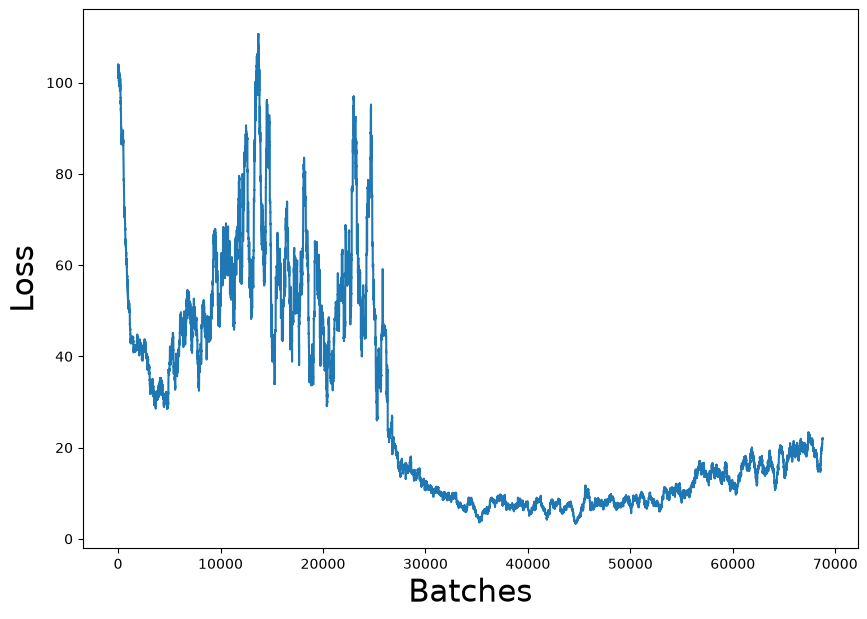

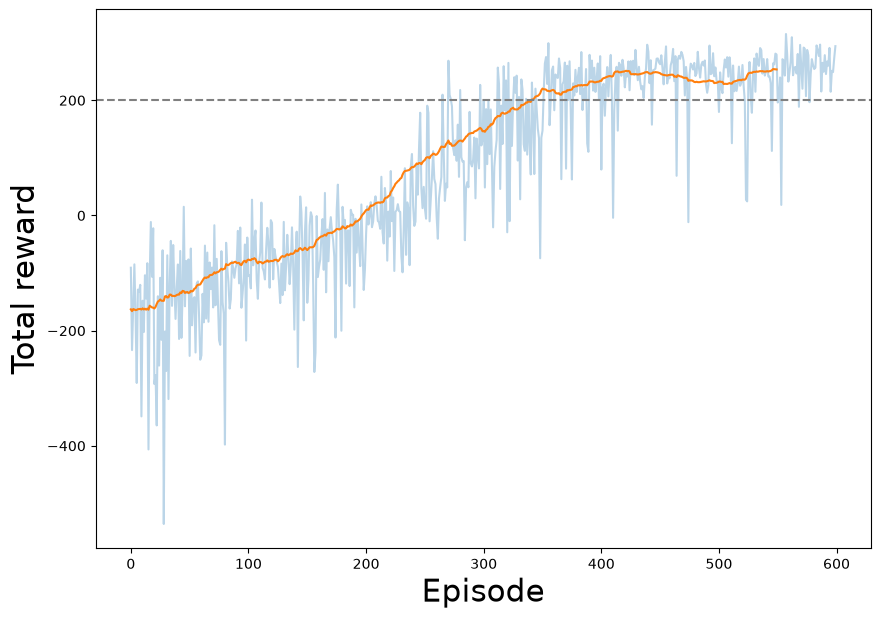

In [6]:
plt.figure(figsize=(10, 7))
plt.plot(running_mean(losses, 500))
plt.xlabel("Batches", fontsize=22)
plt.ylabel("Loss", fontsize=22)

# 新增：分數曲線。DQN 的 loss 會先升後降，不能單獨用來判斷好壞，
# 分數曲線才是真正的學習成果
plt.figure(figsize=(10, 7))
plt.plot(episode_rewards, alpha=0.3)
plt.plot(running_mean(episode_rewards, 50))
plt.axhline(200, color="gray", ls="--")   # 200 分 = 解決
plt.xlabel("Episode", fontsize=22)
plt.ylabel("Total reward", fontsize=22)

##### PyTorch Automatic Differentiation Review

##### Listing 3.4 - Testing the Q-network

In [7]:
def test_model(model, display=False):
    # 修改：display=True 時用 render_mode="human" 開視窗看降落畫面
    test_env = gym.make("LunarLander-v3", render_mode="human" if display else None)
    state, _ = test_env.reset()
    done = False
    total = 0
    while not done:
        state_t = torch.from_numpy(state).float().unsqueeze(0)
        with torch.no_grad():
            action_ = int(np.argmax(model(state_t).numpy()))  # 純 greedy，不探索
        state, reward, terminated, truncated, _ = test_env.step(action_)
        total += reward
        done = terminated or truncated
    test_env.close()
    # 修改：原本回傳 win(True/False)，改成回傳總分；>=200 視為成功降落
    return total

##### Listing 3.5 - DQN with experience replay

##### Listing 3.6 - Testing the performance with experience replay

In [8]:
max_games = 100
scores = [test_model(model) for _ in range(max_games)]
scores = np.array(scores)
print(f"平均分數: {scores.mean():.1f}")
print(f"成功率 (>=200): {(scores >= 200).mean() * 100:.0f}%")
print(f"最終 loss (最後 1000 次平均): {losses[-1000:].mean():.4f}")
test_model(model, display=True)

平均分數: 235.1
成功率 (>=200): 90%
最終 loss (最後 1000 次平均): 18.8809


np.float64(119.97391385908168)

##### Listing 3.7 - Target network

In [9]:
from matplotlib import animation
from IPython.display import Image   # 用來在 notebook 裡顯示 GIF

# 錄下一局遊戲並存成 GIF
# seed=None → 隨機一局；指定 seed → 固定地形與初始推力，可重現同一局
def record_episode(model, path="lunarlander.gif", seed=None):
    # render_mode="rgb_array"：每一步回傳一張畫面（numpy 圖片），不開視窗
    rec_env = gym.make("LunarLander-v3", render_mode="rgb_array")
    state, _ = rec_env.reset(seed=seed)
    frames = [rec_env.render()]                          # 記錄初始畫面
    done, total = False, 0
    while not done:
        state_t = torch.from_numpy(state).float().unsqueeze(0)
        with torch.no_grad():
            action_ = int(np.argmax(model(state_t).numpy()))  # greedy 動作，不探索
        state, reward, terminated, truncated, _ = rec_env.step(action_)
        total += reward
        done = terminated or truncated
        frames.append(rec_env.render())                  # 記錄這一步的畫面
    rec_env.close()

    frames = frames[::2]  # 每 2 格取 1 格，縮小檔案、加快播放
    fig = plt.figure(figsize=(6, 4))
    plt.axis("off")
    img = plt.imshow(frames[0])
    plt.title(f"Total reward: {total:.1f}")
    # 逐格更新畫面，組成動畫
    anim = animation.FuncAnimation(
        fig, lambda k: img.set_data(frames[k]), frames=len(frames), interval=40)
    anim.save(path, writer=animation.PillowWriter(fps=25))  # 存成 GIF，可放簡報
    plt.close(fig)        # 關掉圖，避免 notebook 多顯示一張靜態圖
    print(f"分數 {total:.1f}，已存成 {path}")
    return total

In [10]:
# 用不同 seed 各跑一局（不錄影，速度快），記錄每局分數
def play_seed(model, seed):
    env_ = gym.make("LunarLander-v3")
    state, _ = env_.reset(seed=seed)          # 固定 seed → 固定地形與初始推力
    done, total = False, 0
    while not done:
        state_t = torch.from_numpy(state).float().unsqueeze(0)
        with torch.no_grad():
            action_ = int(np.argmax(model(state_t).numpy()))  # greedy 動作
        state, reward, terminated, truncated, _ = env_.step(action_)
        total += reward
        done = terminated or truncated
    env_.close()
    return total

seed_scores = {s: play_seed(model, s) for s in range(200)}   # 試 200 個 seed
best_seed = max(seed_scores, key=seed_scores.get)            # 分數最高的 seed
worst_seed = min(seed_scores, key=seed_scores.get)           # 分數最低的 seed
print(f"最佳 seed = {best_seed}，分數 {seed_scores[best_seed]:.1f}")
print(f"最差 seed = {worst_seed}，分數 {seed_scores[worst_seed]:.1f}")

最佳 seed = 147，分數 330.3
最差 seed = 137，分數 -134.6


分數 330.3，已存成 best_episode.gif


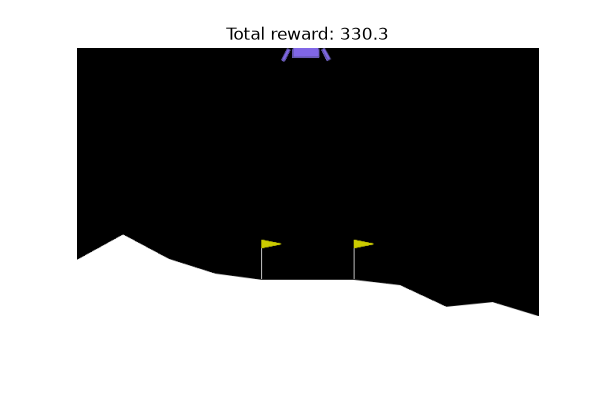

In [11]:
record_episode(model, path="best_episode.gif", seed=best_seed)   # 錄最佳局
Image(filename="best_episode.gif")                                # 在 notebook 播放

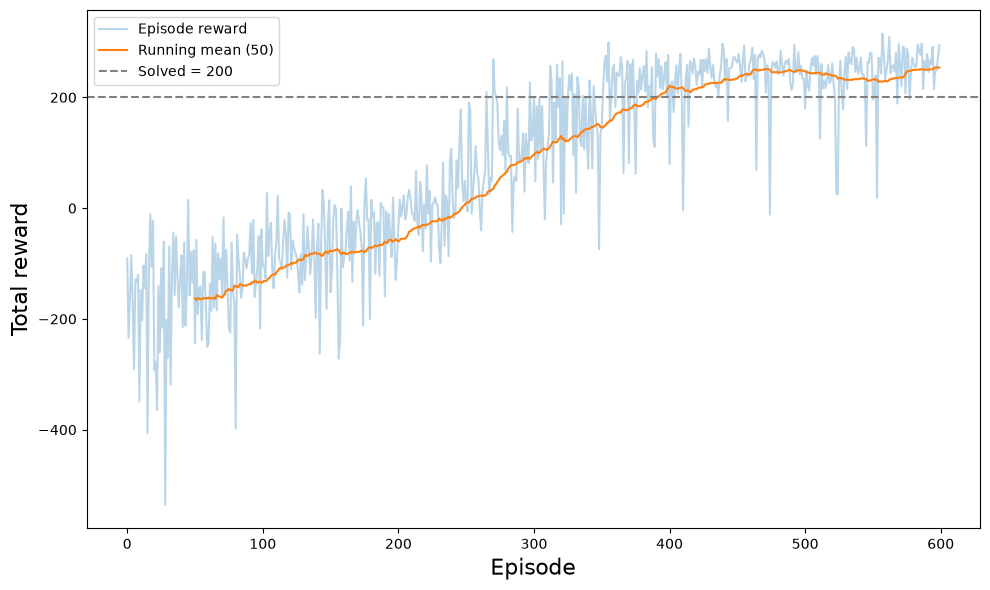

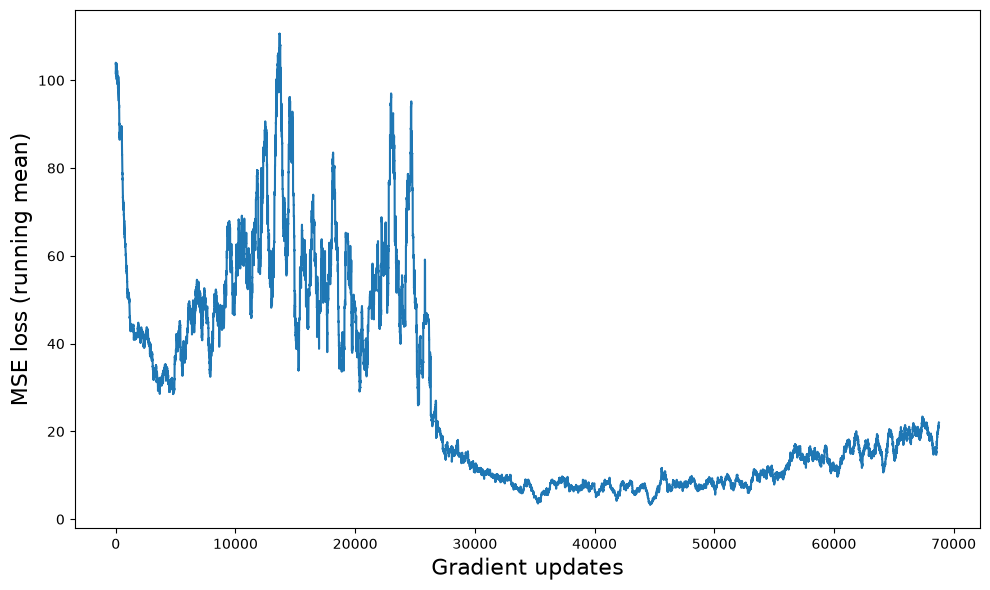

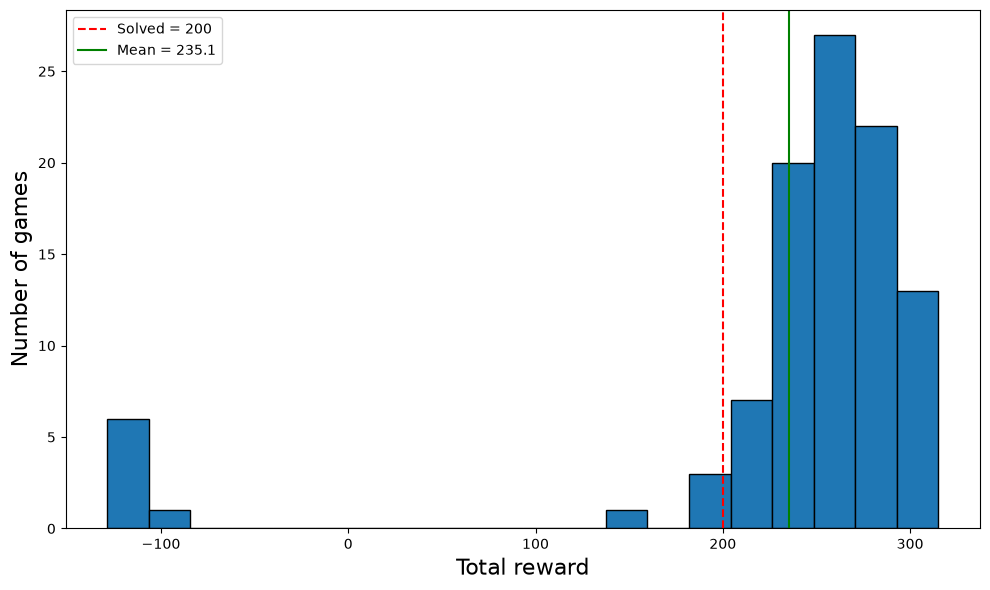

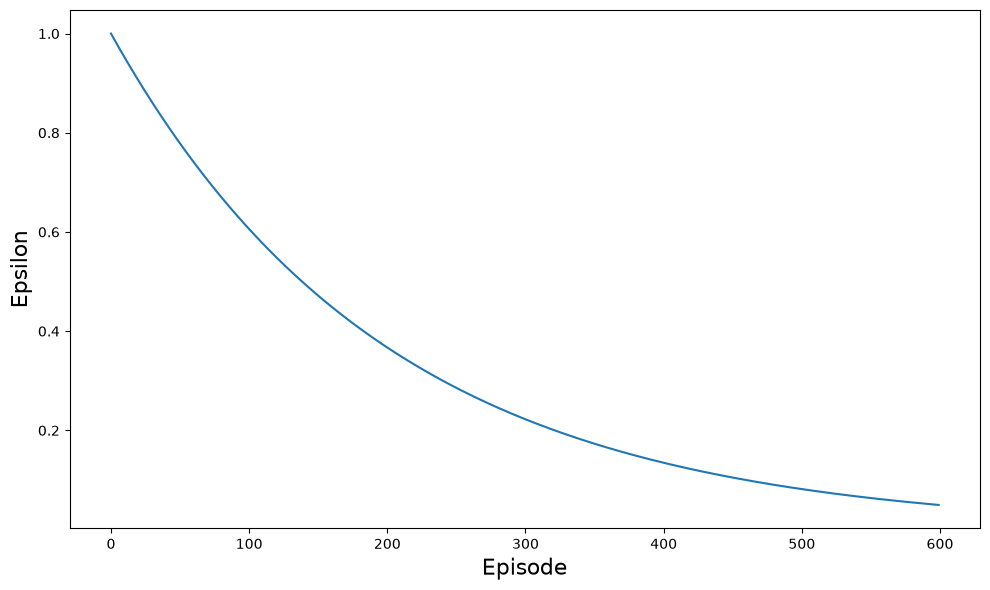

In [12]:
# ---- 1. 分數曲線 ----
rm = running_mean(episode_rewards, 50)        # 先算出移動平均
x_rm = np.arange(len(rm)) + 50                # x 軸長度直接跟著 rm，不會對不上

plt.figure(figsize=(10, 6))
plt.plot(episode_rewards, alpha=0.3, label="Episode reward")
plt.plot(x_rm, rm, label="Running mean (50)")
plt.axhline(200, color="gray", ls="--", label="Solved = 200")
plt.xlabel("Episode", fontsize=16); plt.ylabel("Total reward", fontsize=16)
plt.legend(); plt.tight_layout()
plt.savefig("fig1_reward.png", dpi=150)   # 存成 PNG，給 PPT 用
plt.show()

# ---- 2. Loss 曲線 ----
plt.figure(figsize=(10, 6))
plt.plot(running_mean(losses, 500))
plt.xlabel("Gradient updates", fontsize=16); plt.ylabel("MSE loss (running mean)", fontsize=16)
plt.tight_layout()
plt.savefig("fig2_loss.png", dpi=150)
plt.show()

# ---- 6. 測試分數直方圖（使用格 F 的 scores）----
plt.figure(figsize=(10, 6))
plt.hist(scores, bins=20, edgecolor="black")
plt.axvline(200, color="red", ls="--", label="Solved = 200")
plt.axvline(scores.mean(), color="green", label=f"Mean = {scores.mean():.1f}")
plt.xlabel("Total reward", fontsize=16); plt.ylabel("Number of games", fontsize=16)
plt.legend(); plt.tight_layout()
plt.savefig("fig6_test_hist.png", dpi=150)
plt.show()

# ---- 7. epsilon 遞減曲線（依照格 B 的設定重算）----
eps_curve = [max(0.01, 1.0 * 0.995 ** k) for k in range(len(episode_rewards))]
plt.figure(figsize=(10, 6))
plt.plot(eps_curve)
plt.xlabel("Episode", fontsize=16); plt.ylabel("Epsilon", fontsize=16)
plt.tight_layout()
plt.savefig("fig7_epsilon.png", dpi=150)
plt.show()

分數 -413.5，已存成 before_training.gif


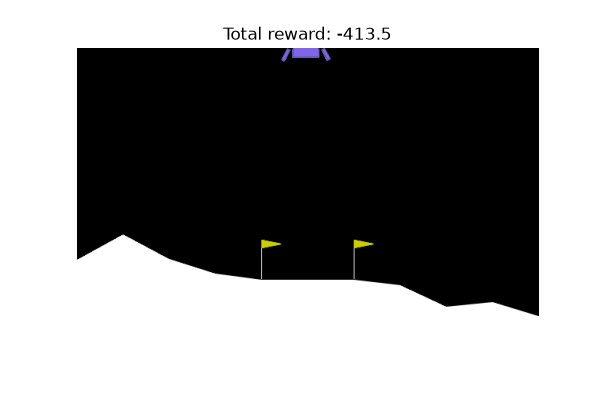

In [13]:
# 建立一個全新、還沒訓練過的網路（權重是隨機的）
untrained = torch.nn.Sequential(
    torch.nn.Linear(8, 150), torch.nn.ReLU(),
    torch.nn.Linear(150, 100), torch.nn.ReLU(),
    torch.nn.Linear(100, 4),
)
# 和最佳局用同一個 seed，同一個地形，對比更明顯
record_episode(untrained, path="before_training.gif", seed=best_seed)
Image(filename="before_training.gif")